# 06 小兔鲜儿 - 微信登录


本篇根据配套讲义 `rabbit-shop/06-登录模块.md` 整理，完成微信手机号授权登录、开发用模拟手机号登录，以及登录后的会员状态保存与页面跳转。

顺序：登录方式 → 登录页静态结构 → 微信登录凭证 → 手机号授权 → 微信登录接口 → 模拟登录 → Pinia 持久化会员信息。

复用 01 的请求封装、会员 Store 和持久化插件。本篇把会员信息的占位类型改为 `LoginResult`，把登录接口结果保存到 Store，让后续请求能携带 Token。

资料来自[课程网盘](https://pan.baidu.com/s/1uhQQvqs9ESRvhEvgzgSUWQ?pwd=9988)，提取码 `9988`，配套包为 `02-笔记.rar`。三张教学图片直接内嵌在 Notebook 中。

| 文件 | 本篇职责 |
| --- | --- |
| `src/pages/login/login.vue` | 微信凭证、授权事件、模拟登录和成功处理 |
| `src/services/login.ts` | 微信登录与模拟登录两个接口 |
| `src/types/member.d.ts` | 登录返回的会员数据类型 |
| `src/stores/modules/member.ts` | 保存、清理与持久化会员信息 |
| `src/utils/http.ts` | 沿用 01 的 Token 请求头与 401 处理 |

原讲义开头提到了文件上传，但本文件的实际教学内容集中在登录与状态管理，未给出上传实现。


## 微信登录

微信小程序提供登录和用户授权等开放能力。课程使用微信登录凭证与手机号授权信息，由业务后端完成会员登录。

要区分两件事：调用 `wx.login` 取得微信登录凭证，与用户主动允许小程序取得手机号。取得登录凭证本身，并不会同时取得昵称、性别或手机号。


### 常见登录方式

常见登录、注册入口包括：

1. 用户名或手机号 + 密码。
2. 手机号 + 验证码。
3. 授权登录。

项目重点实现微信手机号授权登录。用户已经登录微信，在小程序内主动点击手机号按钮，并确认授权，再由后端处理会员身份。

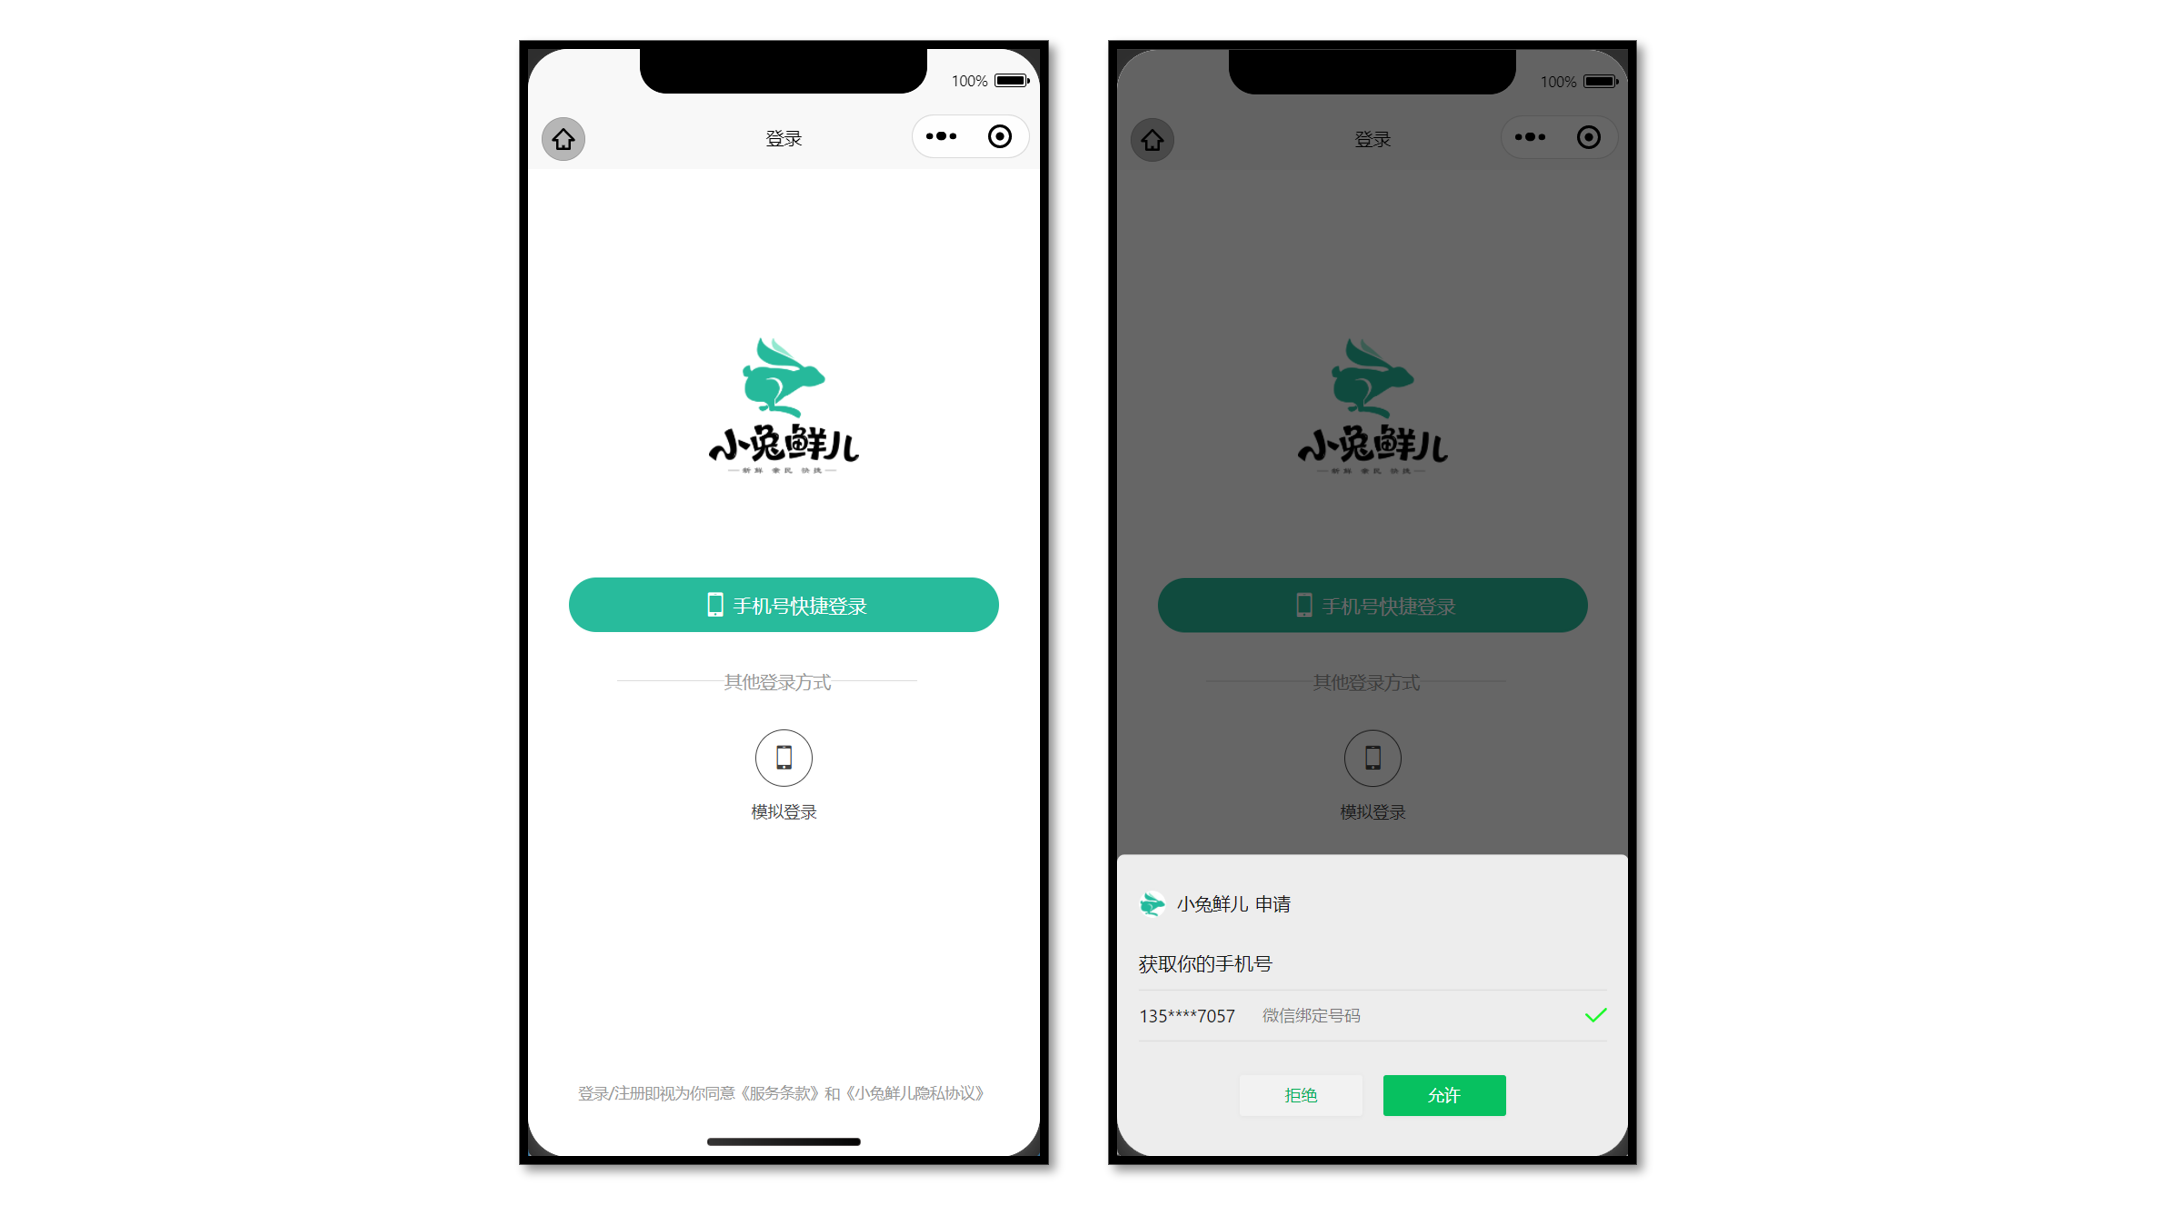


传统账号密码登录通过表单提交账号与密码。原资料也提供这类登录接口，留作课后练习，本篇的主线仍然是微信授权和开发用模拟登录。

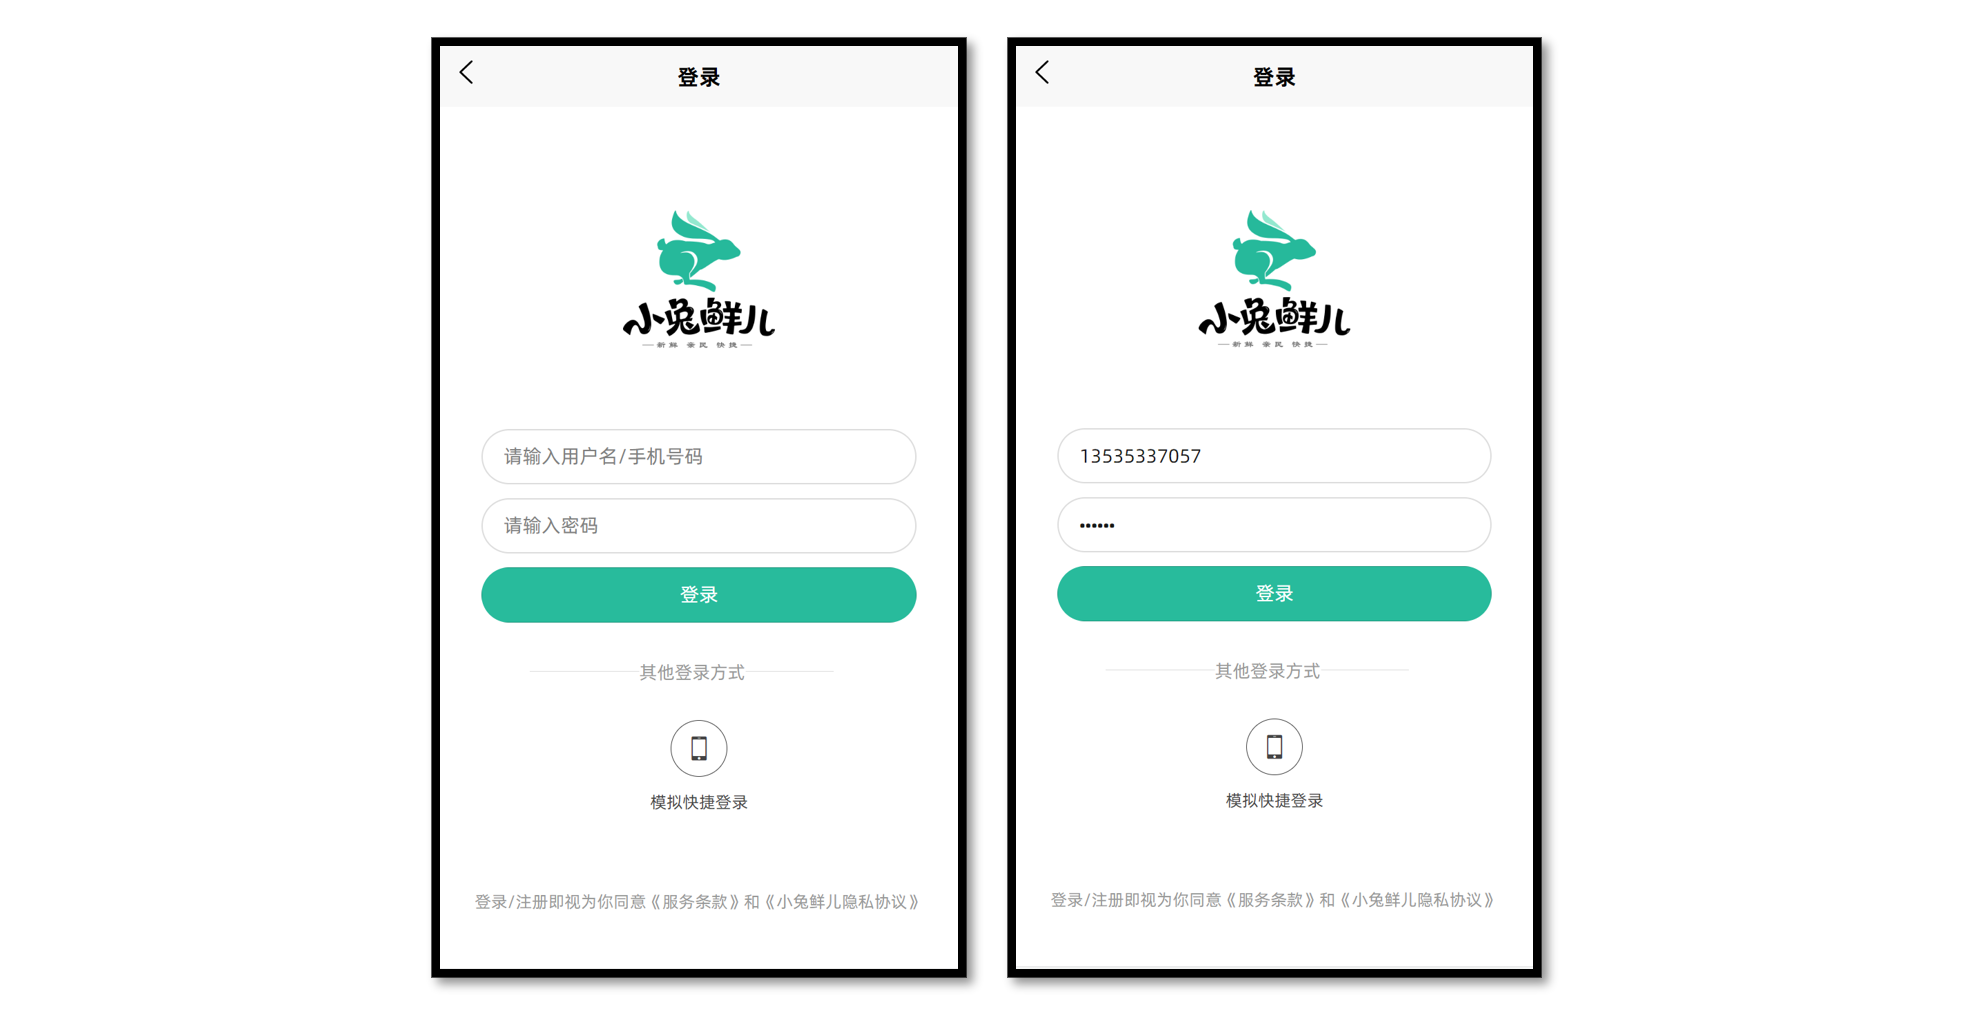


### 登录页静态结构

新建或修改 `src/pages/login/login.vue`，确认 `src/pages.json` 已注册 `pages/login/login`。01 的 401 分支也跳转到这一路由。

先准备原课的页面结构与完整 SCSS：


```vue
<!-- src/pages/login/login.vue -->

<script setup lang="ts">
//
</script>

<template>
  <view class="viewport">
    <view class="logo">
      <image
        src="https://pcapi-xiaotuxian-front-devtest.itheima.net/miniapp/images/logo_icon.png"
      ></image>
    </view>
    <view class="login">
      <!-- 网页端表单登录 -->
      <!-- <input class="input" type="text" placeholder="请输入用户名/手机号码" /> -->
      <!-- <input class="input" type="text" password placeholder="请输入密码" /> -->
      <!-- <button class="button phone">登录</button> -->

      <!-- 小程序端授权登录 -->
      <button class="button phone">
        <text class="icon icon-phone"></text>
        手机号快捷登录
      </button>
      <view class="extra">
        <view class="caption">
          <text>其他登录方式</text>
        </view>
        <view class="options">
          <!-- 通用模拟登录 -->
          <button>
            <text class="icon icon-phone">模拟快捷登录</text>
          </button>
        </view>
      </view>
      <view class="tips">登录/注册即视为你同意《服务条款》和《小兔鲜儿隐私协议》</view>
    </view>
  </view>
</template>

<style lang="scss">
page {
  height: 100%;
}

.viewport {
  display: flex;
  flex-direction: column;
  height: 100%;
  padding: 20rpx 40rpx;
}

.logo {
  flex: 1;
  text-align: center;
  image {
    width: 220rpx;
    height: 220rpx;
    margin-top: 15vh;
  }
}

.login {
  display: flex;
  flex-direction: column;
  height: 60vh;
  padding: 40rpx 20rpx 20rpx;

  .input {
    width: 100%;
    height: 80rpx;
    font-size: 28rpx;
    border-radius: 72rpx;
    border: 1px solid #ddd;
    padding-left: 30rpx;
    margin-bottom: 20rpx;
  }

  .button {
    display: flex;
    align-items: center;
    justify-content: center;
    width: 100%;
    height: 80rpx;
    font-size: 28rpx;
    border-radius: 72rpx;
    color: #fff;
    .icon {
      font-size: 40rpx;
      margin-right: 6rpx;
    }
  }

  .phone {
    background-color: #28bb9c;
  }

  .wechat {
    background-color: #06c05f;
  }

  .extra {
    flex: 1;
    padding: 70rpx 70rpx 0;
    .caption {
      width: 440rpx;
      line-height: 1;
      border-top: 1rpx solid #ddd;
      font-size: 26rpx;
      color: #999;
      position: relative;
      text {
        transform: translate(-40%);
        background-color: #fff;
        position: absolute;
        top: -12rpx;
        left: 50%;
      }
    }

    .options {
      display: flex;
      justify-content: center;
      align-items: center;
      margin-top: 70rpx;
      button {
        padding: 0;
        background-color: transparent;
      }
    }

    .icon {
      font-size: 24rpx;
      color: #444;
      display: flex;
      flex-direction: column;
      align-items: center;

      &::before {
        display: flex;
        align-items: center;
        justify-content: center;
        width: 80rpx;
        height: 80rpx;
        margin-bottom: 6rpx;
        font-size: 40rpx;
        border: 1rpx solid #444;
        border-radius: 50%;
      }
    }
    .icon-weixin::before {
      border-color: #06c05f;
      color: #06c05f;
    }
  }
}

.tips {
  position: absolute;
  bottom: 80rpx;
  left: 20rpx;
  right: 20rpx;
  font-size: 22rpx;
  color: #999;
  text-align: center;
}
</style>
```

页面包括 Logo、手机号快捷登录、模拟登录入口和底部协议文案。表单登录输入框暂时以注释保留。

当前按钮只有外观，后续分别绑定授权事件与普通点击事件。动态改造时保留这里的完整模板和样式，逐步替换脚本并增加按钮事件。


### 获取微信登录凭证

前端调用 [wx.login()](https://developers.weixin.qq.com/miniprogram/dev/api/open-api/login/wx.login.html) 取得 `code`，后端再用这个凭证与微信服务器交互，建立对应的[微信登录态](https://developers.weixin.qq.com/miniprogram/dev/framework/open-ability/login.html)。

在登录页的 `<script setup lang="ts">` 中：


```vue
<script setup lang="ts">
import { onLoad } from '@dcloudio/uni-app'

// 获取 code 登录凭证
let code = ''
onLoad(async () => {
  const res = await wx.login()
  code = res.code
})
</script>
```

`onLoad` 提前取得凭证，保存在页面变量 `code` 中，后面授权手机号时一起交给业务后端。

> **原课注意事项**：不要把 `wx.login()` 放进 `getphonenumber` 事件回调中再调用，原课提示这样可能出现错误。按本课程的流程，先取得微信凭证，再处理手机号授权。

这段是微信小程序端代码，`wx` 是平台提供的全局对象。跨端练习时，要把微信专用逻辑限定在微信小程序环境。


### 凭证、手机号信息与 Token 的区别

| 数据 | 来源 | 用途 |
| --- | --- | --- |
| `code` | `wx.login()` | 后端与微信服务器交互 |
| `encryptedData`、`iv` | 原课的手机号授权事件 | 后端处理手机号信息 |
| `token` | 业务登录接口返回的 `LoginResult` | 后续调用项目的会员接口 |
| 昵称、头像等会员字段 | 项目的登录返回结构 | 保存与展示会员信息 |

`wx.login` 成功只取得微信登录凭证，项目登录还要调用后面的业务接口。用于请求头 `Authorization` 的是业务后端返回的 `token`。

本课接口使用 `code + encryptedData + iv` 的加密数据流程。微信手机号能力的接口与返回字段可能随平台版本变化，跟做本接口时应同时对照后端参数约定与官方文档，不能把不同用途的凭证混用。


### 用户主动授权手机号码

原课要求用户主动点击按钮，并允许手机号申请，才继续取得授权信息。前端负责收集事件数据，后端按课程接口处理手机号并关联会员身份。

按钮声明 `open-type="getPhoneNumber"`，通过 `@getphonenumber` 监听结果：


```vue
<script setup lang="ts">
// 获取用户手机号码
const onGetphonenumber: UniHelper.ButtonOnGetphonenumber = (ev) => {
  console.log(ev)
}
</script>

<template>
  <view class="viewport">
    <view class="login">
      <button class="button phone" open-type="getPhoneNumber" @getphonenumber="onGetphonenumber">
        <text class="icon icon-phone"></text>
        手机号快捷登录
      </button>
    </view>
  </view>
</template>
```

这一阶段先观察授权事件是否按预期返回；它还没有请求业务登录接口。

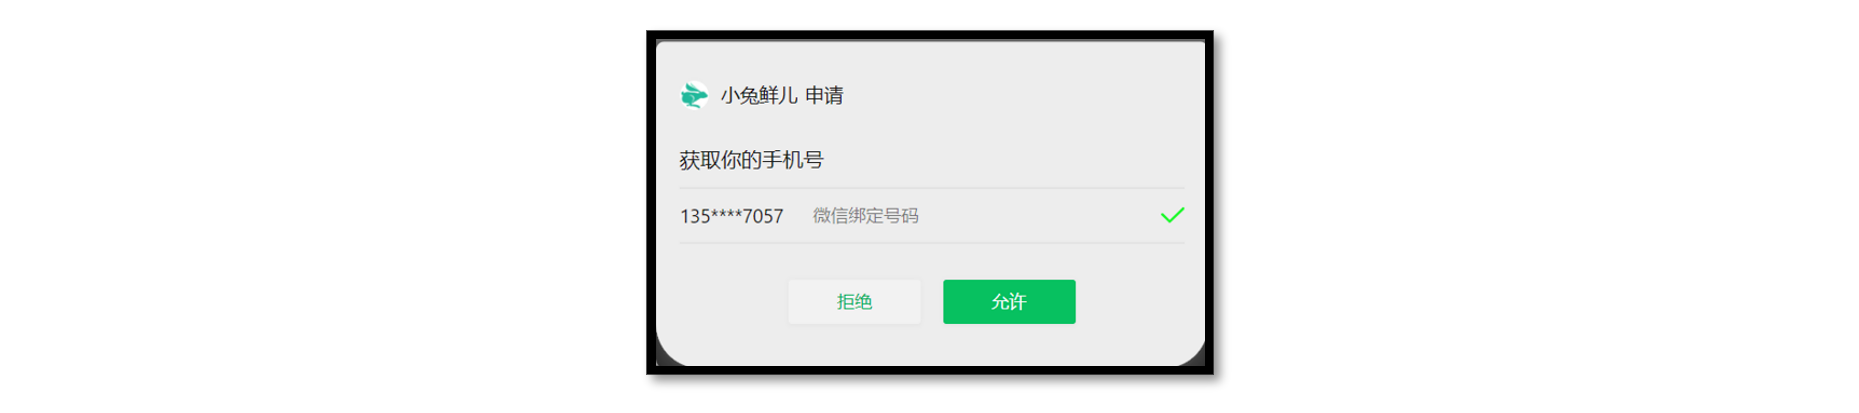


> **原课能力范围说明**：讲义写明手机号能力面向非个人开发者、完成认证的小程序，个人学习账号可能无法唤起授权界面。这里保留课程当时的说明；实际资格、开放范围和调用要求，以[当前微信官方手机号文档](https://developers.weixin.qq.com/miniprogram/dev/framework/open-ability/getPhoneNumber.html)及账号后台为准。

无法使用真实手机号授权时，可继续使用后文提供的模拟登录接口完成 Store 和后续业务练习。

用户也可以拒绝授权。后面的原课示例通过非空断言读取 `encryptedData` 和 `iv`，它假定授权成功；非空断言不会在运行时检查参数，拒绝或字段缺失时，不应直接继续调用这套登录接口。


### 微信登录接口（原课生产流程）

课程接口为 `POST /login/wxMin`：

| Body 字段 | 是否必需 | 来源 |
| --- | --- | --- |
| `code` | 是 | `wx.login` 返回的登录凭证 |
| `encryptedData` | 是 | 原课手机号授权事件 |
| `iv` | 是 | 原课手机号授权事件 |

新建 `src/services/login.ts`：


```typescript
// src/services/login.ts

import type { LoginResult } from '@/types/member'
import { http } from '@/utils/http'

type LoginParams = {
  code: string
  encryptedData: string
  iv: string
}
/**
 * 小程序登录
 * @param data 请求参数
 */
export const postLoginWxMinAPI = (data: LoginParams) => {
  return http<LoginResult>({
    method: 'POST',
    url: '/login/wxMin',
    data,
  })
}
```

`LoginParams` 把三个参数限定为字符串；`http<LoginResult>` 使用 01 的请求函数，业务会员信息从 `res.result` 中取得。

前端不承担原课的手机号解密，相关微信服务器交互由后端处理。


### 登录结果类型

新建 `src/types/member.d.ts`：


```typescript
// src/types/member.d.ts

/** 小程序登录 登录用户信息 */
export type LoginResult = {
  /** 用户ID */
  id: number
  /** 头像  */
  avatar: string
  /** 账户名  */
  account: string
  /** 昵称 */
  nickname?: string
  /** 手机号 */
  mobile: string
  /** 登录凭证 */
  token: string
}
```

登录结果包含用户 ID、头像、账号、手机号、Token 和可选昵称。`nickname?` 表示返回对象里可能没有昵称，后续展示时需要考虑这一点。

本课 `id` 按原类型定义保留为 `number`。`token` 是后续会员接口需要的项目登录凭证。


### 授权事件中调用业务登录

将获取凭证和授权事件连接起来。下面是原课这一阶段的页面片段：


```vue
<!-- src/pages/login/login.vue -->

<script setup lang="ts">
import { postLoginWxMinAPI } from '@/services/login'
import { onLoad } from '@dcloudio/uni-app'

// 获取 code 登录凭证
let code = ''
onLoad(async () => {
  const res = await wx.login()
  code = res.code
})

// 获取用户手机号码
const onGetphonenumber: UniHelper.ButtonOnGetphonenumber = async (ev) => {
  // 获取参数
  const encryptedData = ev.detail.encryptedData!
  const iv = ev.detail.iv!
  // 登录请求
  await postLoginWxMinAPI({ code, encryptedData, iv })
  // 成功提示
  uni.showToast({ icon: 'none', title: '登录成功' })
}
</script>

<template>
  <view class="viewport">
    <view class="login">
      <button class="button phone" open-type="getPhoneNumber" @getphonenumber="onGetphonenumber">
        <text class="icon icon-phone"></text>
        手机号快捷登录
      </button>
    </view>
  </view>
</template>
```

流程是：页面取得微信 `code` → 用户点击并允许手机号授权 → 读取 `encryptedData` 和 `iv` → 发送业务登录请求 → 提示成功。

此片段只展示成功提示，尚未保存会员信息。最后一节会把结果交给统一的 `loginSuccess`。

原代码通过 `!` 假定参数已存在，也没有控制“凭证仍在请求中”的点击时机。跟做时应确认 `code` 已取得、用户确实允许授权，并注意凭证失效或重复使用带来的失败。


### 模拟手机号登录（开发练习）

为继续学习登录后的业务，课程后端提供[内部测试接口](https://apifox.com/apidoc/shared-0e6ee326-d646-41bd-9214-29dbf47648fa/api-43426851)，只提交模拟手机号即可返回与微信登录相同格式的会员数据。

| 项目 | 内容 |
| --- | --- |
| 方法与路径 | `POST /login/wxMin/simple` |
| Body 参数 | `phoneNumber`，必需，字符串 |
| 返回业务类型 | 同样为 `LoginResult` |
| 本课用途 | 开发与课程练习 |

在已有 `src/services/login.ts` 中追加：


```typescript
/**
 * 小程序登录_内测版
 * @param phoneNumber 模拟手机号码
 */
export const postLoginWxMinSimpleAPI = (phoneNumber: string) => {
  return http<LoginResult>({
    method: 'POST',
    url: '/login/wxMin/simple',
    data: {
      phoneNumber,
    },
  })
}
```

沿用该文件顶部的 `http`、`LoginResult` 导入。模拟流程不要求本次点击提供 `wx.login` 的 `code`、`encryptedData` 或 `iv`。

这是课程的内测入口。正常授权与模拟登录最终都返回会员资料，所以可以复用同一个成功处理函数。


### 用户信息持久化存储

01 已注册 Pinia 持久化插件，并适配 `uni.getStorageSync` / `uni.setStorageSync`。本篇在用户登录成功后保存会员数据，并把 Store 的占位类型替换成真实的 `LoginResult`。

更新 `src/stores/modules/member.ts`：


```typescript
// src/stores/modules/member.ts

import type { LoginResult } from '@/types/member'
import { defineStore } from 'pinia'
import { ref } from 'vue'

// 定义 Store
export const useMemberStore = defineStore(
  'member',
  () => {
    // 会员信息
    const profile = ref<LoginResult>()

    // 保存会员信息，登录时使用
    const setProfile = (val: LoginResult) => {
      profile.value = val
    }

    // 清理会员信息，退出时使用
    const clearProfile = () => {
      profile.value = undefined
    }

    // 记得 return
    return { profile, setProfile, clearProfile }
  },
  {
    // 小程序端配置
    persist: {
      storage: {
        getItem(key) {
          return uni.getStorageSync(key)
        },
        setItem(key, value) {
          uni.setStorageSync(key, value)
        },
      },
    },
  },
)
```

| 成员 | 职责 |
| --- | --- |
| `profile` | 当前会员信息，初始可为空 |
| `setProfile(profile)` | 保存登录结果 |
| `clearProfile()` | 退出或登录失效时清理 |
| `persist.storage` | 使用多端本地存储保持状态 |

`ref<LoginResult>()` 与 `setProfile(val: LoginResult)` 提供会员字段的类型提示。插件负责序列化和状态恢复，页面只需要更新 Store，无需另外手写一份重复的本地存储逻辑。

仍保留 01 的 Pinia 实例、插件注册和 `app.use(pinia)`；替换这个会员模块不等于重新创建另一套 Store。


### 登录页统一处理成功结果

下面是原课最后的登录页脚本，替换静态页中的脚本，保留静态模板和 SCSS：


```vue
<script setup lang="ts">
import { postLoginWxMinAPI, postLoginWxMinSimpleAPI } from '@/services/login'
import { useMemberStore } from '@/stores'
import type { LoginResult } from '@/types/member'
import { onLoad } from '@dcloudio/uni-app'

// 获取 code 登录凭证
let code = ''
onLoad(async () => {
  const res = await wx.login()
  code = res.code
})

// 获取用户手机号码（企业中写法）
const onGetphonenumber: UniHelper.ButtonOnGetphonenumber = async (ev) => {
  const encryptedData = ev.detail.encryptedData!
  const iv = ev.detail.iv!
  const res = await postLoginWxMinAPI({ code, encryptedData, iv })
  loginSuccess(res.result)
}

// 模拟手机号码快捷登录（开发练习）
const onGetphonenumberSimple = async () => {
  const res = await postLoginWxMinSimpleAPI('13123456789')
  loginSuccess(res.result)
}

const loginSuccess = (profile: LoginResult) => {
  // 保存会员信息
  const memberStore = useMemberStore()
  memberStore.setProfile(profile)
  // 成功提示
  uni.showToast({ icon: 'success', title: '登录成功' })
  setTimeout(() => {
    // 页面跳转
    uni.switchTab({ url: '/pages/my/my' })
  }, 500)
}
</script>
```

授权登录与模拟登录都取得 `res.result`，然后调用 `loginSuccess`：

1. 从 `useMemberStore` 取得会员 Store。
2. 通过 `setProfile` 保存完整会员资料，包括 Token。
3. 显示成功提示。
4. 等待 `500` 毫秒，切换到底部导航的“我的”页面 `/pages/my/my`。

“我的”是 tabBar 页面，因此使用 `uni.switchTab`。这里是跳转到“我的”，没有实现登录后返回先前业务页面。

会员信息保存之后，01 的请求拦截器会读取 `memberStore.profile?.token`，给后续请求添加 `Authorization`。遇到 401 时则由 01 的处理清理会员状态并跳转登录页。


### 把两个按钮与最终脚本连接起来

原稿的最后一段仅给出脚本，没有重新列出静态模板。下面按脚本方法名补齐按钮绑定，合并回原静态页中，Logo、协议文案和 SCSS 继续保留：


```vue
<template>
  <view class="login">
    <!-- 微信小程序端：保留在微信平台内 -->
    <!-- #ifdef MP-WEIXIN -->
    <button
      class="button phone"
      open-type="getPhoneNumber"
      @getphonenumber="onGetphonenumber"
    >
      <text class="icon icon-phone"></text>
      手机号快捷登录
    </button>
    <!-- #endif -->

    <!-- 原静态页“其他登录方式”中的模拟按钮 -->
    <view class="extra">
      <view class="caption">
        <text>其他登录方式</text>
      </view>
      <view class="options">
        <button @tap="onGetphonenumberSimple">
          <text class="icon icon-phone">模拟快捷登录</text>
        </button>
      </view>
    </view>
  </view>
</template>
```

授权按钮使用 `@getphonenumber`，模拟按钮使用普通点击事件 `@tap`；两种入口的事件不同，不能把模拟按钮也设为手机号授权按钮。

原课脚本中的 `wx.login` 是微信专用代码。需要在 H5 等平台练习模拟登录时，按 uni-app 条件编译保护原有的凭证获取部分，例如：


```typescript
let code = ''
// #ifdef MP-WEIXIN
onLoad(async () => {
  const res = await wx.login()
  code = res.code
})
// #endif
```

该片段替换原来的 `let code` 和 `onLoad` 凭证段，不重复追加声明；上面的微信按钮也已给出对应的条件编译范围。模拟接口自身可以使用公共请求函数，原课没有在完整脚本中展开这层平台隔离。


## 本篇完成检查

- [ ] 登录页路由已注册，静态模板与完整 SCSS 保留。
- [ ] 微信登录凭证在页面加载时取得，与业务 Token 的用途区分清楚。
- [ ] 手机号授权按钮使用正确的 `open-type` 和事件，参数与课程接口一致。
- [ ] 授权拒绝、凭证未就绪等情况不会被非空断言误当成成功。
- [ ] 模拟按钮绑定 `onGetphonenumberSimple`，用于开发练习。
- [ ] 两个登录函数都把 `res.result` 交给统一成功处理。
- [ ] Store 保存完整会员资料，重新启动后可从持久化存储恢复。
- [ ] 登录成功后切换到“我的”，后续请求携带会员 Token。
- [ ] 跨端使用模拟登录时，微信专用调用与按钮限定在微信环境。

本篇完成登录与会员信息保存，接下来按原课进入用户模块。
